In [3]:
import pandas as pd
import numpy as np

# 1. Load the dataset
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

# 2. Inspect dimensions (rows, columns)
print("Dataset Shape:", df.shape)

# 3. Inspect data types and non-null counts
print("\nData Info:")
print(df.info())

# 4. Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check for duplicate rows
print("\nDuplicate Rows Count:", df.duplicated().sum())

# 6. Clean duplicates (if any)
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Dataset Shape: (1338, 7)

Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate Rows Count: 1
Shape after removing duplicates: (1337, 7)


               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    53.130000     5.000000  63770.428010


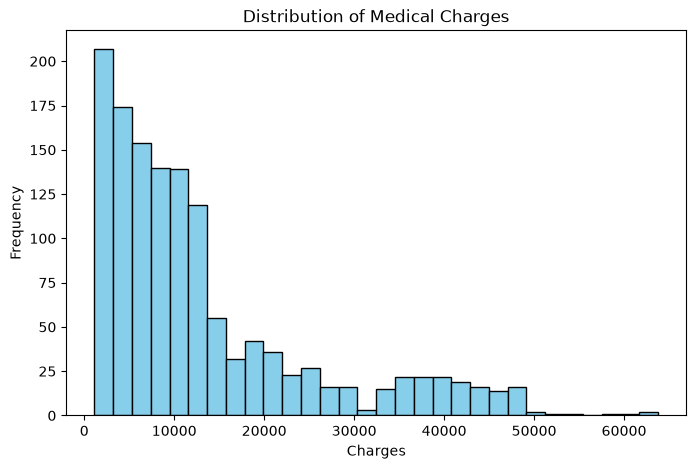

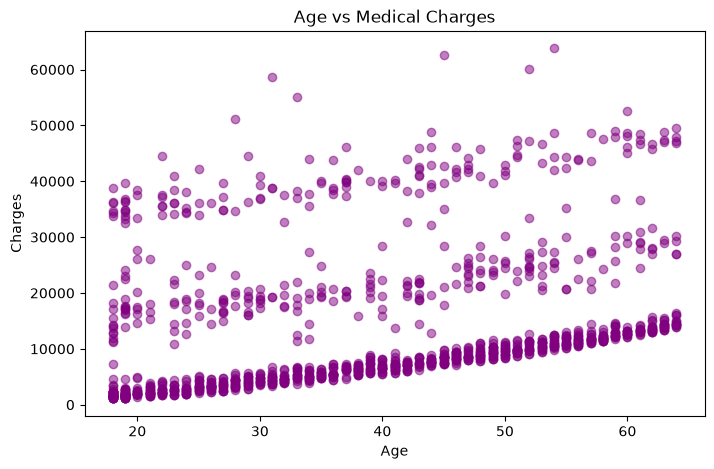


Correlation Matrix:
               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


In [4]:
import matplotlib.pyplot as plt

# 1. Summary statistics for numerical columns
print(df.describe())

# 2. Visualizing distribution of the target variable (charges)
plt.figure(figsize=(8, 5))
plt.hist(df['charges'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Medical Charges')
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.show()

# 3. Visualizing Age vs Charges
plt.figure(figsize=(8, 5))
plt.scatter(df['age'], df['charges'], alpha=0.5, color='purple')
plt.title('Age vs Medical Charges')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.show()

# 4. Correlation matrix for numerical variables
print("\nCorrelation Matrix:")
print(df[['age', 'bmi', 'children', 'charges']].corr())

In [5]:
from sklearn.model_selection import train_test_split

# 1. Convert categorical columns to numerical values (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# 2. Define Features (X) and Target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# 3. Split the dataset into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Print shapes to verify
print("Training set shape (X_train):", X_train.shape)
print("Testing set shape (X_test):", X_test.shape)

Training set shape (X_train): (1069, 8)
Testing set shape (X_test): (268, 8)


# Part 2: Baseline and Linear Regression Models

--- 1. Baseline Model ---
MAE: 9861.80 | RMSE: 13612.43 | R²: -0.01

--- 2. Simple Linear Regression (Age) ---
MAE: 9657.79 | RMSE: 12894.78 | R²: 0.10

--- 3. Multiple Linear Regression ---
MAE: 4177.05 | RMSE: 5956.34 | R²: 0.81 | Adj-R²: 0.80

--- 4. Polynomial Regression (Degree 2) ---
MAE: 2867.32 | RMSE: 4646.06 | R²: 0.88 | Adj-R²: 0.86


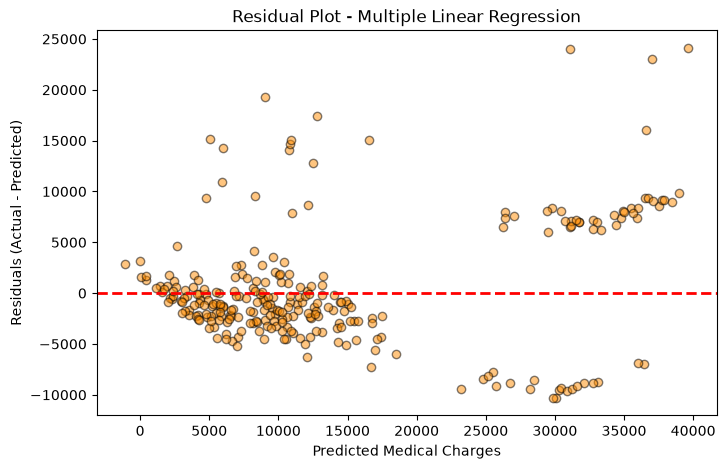

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# 1. Baseline Model (Predicting the mean of y_train for all test samples)
baseline_pred = np.full(shape=y_test.shape, fill_value=y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print("--- 1. Baseline Model ---")
print(f"MAE: {baseline_mae:.2f} | RMSE: {baseline_rmse:.2f} | R²: {baseline_r2:.2f}")

# 2. Simple Linear Regression (using 'age' as the single predictor)
X_train_simple = X_train[['age']]
X_test_simple = X_test[['age']]

slr = LinearRegression()
slr.fit(X_train_simple, y_train)
slr_pred = slr.predict(X_test_simple)

slr_mae = mean_absolute_error(y_test, slr_pred)
slr_rmse = np.sqrt(mean_squared_error(y_test, slr_pred))
slr_r2 = r2_score(y_test, slr_pred)

print("\n--- 2. Simple Linear Regression (Age) ---")
print(f"MAE: {slr_mae:.2f} | RMSE: {slr_rmse:.2f} | R²: {slr_r2:.2f}")

# 3. Multiple Linear Regression (using all available features)
mlr = LinearRegression()
mlr.fit(X_train, y_train)
mlr_pred = mlr.predict(X_test)

mlr_mae = mean_absolute_error(y_test, mlr_pred)
mlr_rmse = np.sqrt(mean_squared_error(y_test, mlr_pred))
mlr_r2 = r2_score(y_test, mlr_pred)

# Calculate Adjusted R-squared for MLR
n = X_test.shape[0]
p_mlr = X_test.shape[1]
mlr_adj_r2 = 1 - ((1 - mlr_r2) * (n - 1) / (n - p_mlr - 1))

print("\n--- 3. Multiple Linear Regression ---")
print(f"MAE: {mlr_mae:.2f} | RMSE: {mlr_rmse:.2f} | R²: {mlr_r2:.2f} | Adj-R²: {mlr_adj_r2:.2f}")

# 4. Polynomial Regression (Degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
poly_pred = poly_reg.predict(X_test_poly)

poly_mae = mean_absolute_error(y_test, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))
poly_r2 = r2_score(y_test, poly_pred)

# Calculate Adjusted R-squared for Polynomial Regression
p_poly = X_train_poly.shape[1]
poly_adj_r2 = 1 - ((1 - poly_r2) * (n - 1) / (n - p_poly - 1))

print("\n--- 4. Polynomial Regression (Degree 2) ---")
print(f"MAE: {poly_mae:.2f} | RMSE: {poly_rmse:.2f} | R²: {poly_r2:.2f} | Adj-R²: {poly_adj_r2:.2f}")

# 5. Residual Analysis Plot for Multiple Linear Regression
residuals = y_test - mlr_pred
plt.figure(figsize=(8, 5))
plt.scatter(mlr_pred, residuals, alpha=0.5, color='darkorange', edgecolor='black')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.title('Residual Plot - Multiple Linear Regression')
plt.xlabel('Predicted Medical Charges')
plt.ylabel('Residuals (Actual - Predicted)')
plt.show()

# Part 3: Regularization and Advanced Regression Models

In [8]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb  # XGBoost model

# Dictionary to store performance results for comparison
model_results = {}

# 1. Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_poly, y_train) # Using polynomial features for regularized linear models
ridge_pred = ridge.predict(X_test_poly)
model_results['Ridge'] = {
    'MAE': mean_absolute_error(y_test, ridge_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, ridge_pred)),
    'R2': r2_score(y_test, ridge_pred)
}

# 2. Lasso Regression
lasso = Lasso(alpha=1.0, max_iter=10000)
lasso.fit(X_train_poly, y_train)
lasso_pred = lasso.predict(X_test_poly)
model_results['Lasso'] = {
    'MAE': mean_absolute_error(y_test, lasso_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, lasso_pred)),
    'R2': r2_score(y_test, lasso_pred)
}

# 3. Elastic Net Regression
enet = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
enet.fit(X_train_poly, y_train)
enet_pred = enet.predict(X_test_poly)
model_results['ElasticNet'] = {
    'MAE': mean_absolute_error(y_test, enet_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, enet_pred)),
    'R2': r2_score(y_test, enet_pred)
}

# 4. Decision Tree Regressor (using original X_train/X_test)
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
model_results['DecisionTree'] = {
    'MAE': mean_absolute_error(y_test, dt_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, dt_pred)),
    'R2': r2_score(y_test, dt_pred)
}

# 5. Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
model_results['RandomForest'] = {
    'MAE': mean_absolute_error(y_test, rf_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, rf_pred)),
    'R2': r2_score(y_test, rf_pred)
}

# 6. Gradient Boosting Regressor
gbr = GradientBoostingRegressor(n_estimators=100, random_state=42)
gbr.fit(X_train, y_train)
gbr_pred = gbr.predict(X_test)
model_results['GradientBoosting'] = {
    'MAE': mean_absolute_error(y_test, gbr_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, gbr_pred)),
    'R2': r2_score(y_test, gbr_pred)
}

# 7. XGBoost Regressor
xg_reg = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
xg_reg.fit(X_train, y_train)
xg_pred = xg_reg.predict(X_test)
model_results['XGBoost'] = {
    'MAE': mean_absolute_error(y_test, xg_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, xg_pred)),
    'R2': r2_score(y_test, xg_pred)
}

# Print summary comparison table
print(f"{'Model':<20} | {'MAE':<10} | {'RMSE':<10} | {'R2':<10}")
print("-" * 56)
for name, metrics in model_results.items():
    print(f"{name:<20} | {metrics['MAE']:<10.2f} | {metrics['RMSE']:<10.2f} | {metrics['R2']:<10.2f}")

Model                | MAE        | RMSE       | R2        
--------------------------------------------------------
Ridge                | 2867.11    | 4641.28    | 0.88      
Lasso                | 2862.61    | 4639.98    | 0.88      
ElasticNet           | 3027.52    | 4808.93    | 0.87      
DecisionTree         | 2713.54    | 5761.39    | 0.82      
RandomForest         | 2631.95    | 4696.32    | 0.88      
GradientBoosting     | 2517.47    | 4268.28    | 0.90      
XGBoost              | 2843.47    | 4975.48    | 0.87      


# Part 4: Cross-Validation, Bias–Variance and Model Diagnostics

--- 5-Fold Cross-Validation R² Scores ---
Random Forest CV R² Scores: [0.78384428 0.81484859 0.86563511 0.78437879 0.83174864]
Random Forest Mean CV R²: 0.82 (+/- 0.06)

Gradient Boosting CV R² Scores: [0.81100028 0.83378068 0.88100492 0.80612668 0.83888244]
Gradient Boosting Mean CV R²: 0.83 (+/- 0.05)

--- Training vs Testing Performance (Gradient Boosting) ---
Training R²: 0.89
Testing R²: 0.90
(A small gap indicates a healthy model with balanced bias and variance.)

--- Top 5 Largest Prediction Errors (Gradient Boosting) ---
Test Index 79 | Actual: 30260.00 | Predicted: 13654.16 | Error: 16605.84
Test Index 254 | Actual: 60021.40 | Predicted: 43326.63 | Error: 16694.77
Test Index 175 | Actual: 32734.19 | Predicted: 15577.48 | Error: 17156.71
Test Index 34 | Actual: 63770.43 | Predicted: 46389.97 | Error: 17380.46
Test Index 124 | Actual: 28340.19 | Predicted: 9042.79 | Error: 19297.40


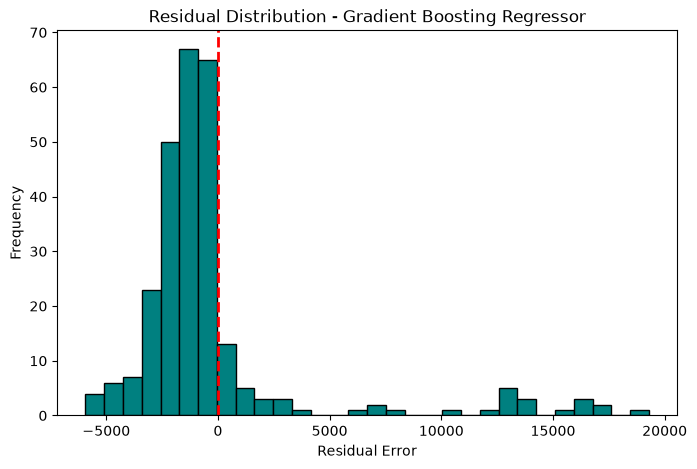

In [10]:
from sklearn.model_selection import cross_val_score, KFold

# 1. K-Fold Cross-Validation for Shortlisted Models (Random Forest & Gradient Boosting)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("--- 5-Fold Cross-Validation R² Scores ---")

rf_cv_scores = cross_val_score(rf, X_train, y_train, cv=kf, scoring='r2')
print(f"Random Forest CV R² Scores: {rf_cv_scores}")
print(f"Random Forest Mean CV R²: {rf_cv_scores.mean():.2f} (+/- {rf_cv_scores.std()*2:.2f})\n")

gbr_cv_scores = cross_val_score(gbr, X_train, y_train, cv=kf, scoring='r2')
print(f"Gradient Boosting CV R² Scores: {gbr_cv_scores}")
print(f"Gradient Boosting Mean CV R²: {gbr_cv_scores.mean():.2f} (+/- {gbr_cv_scores.std()*2:.2f})\n")

# 2. Overfitting Check (Training vs Testing Performance for Gradient Boosting)
gbr_train_pred = gbr.predict(X_train)
gbr_test_pred = gbr.predict(X_test)

train_r2 = r2_score(y_train, gbr_train_pred)
test_r2 = r2_score(y_test, gbr_test_pred)

print("--- Training vs Testing Performance (Gradient Boosting) ---")
print(f"Training R²: {train_r2:.2f}")
print(f"Testing R²: {test_r2:.2f}")
print("(A small gap indicates a healthy model with balanced bias and variance.)")

# 3. Detailed Residual Diagnostics & Identifying Large Errors
residuals = y_test - gbr_test_pred
absolute_errors = np.abs(residuals)

# Find top 5 observations with the largest prediction errors
largest_errors_idx = np.argsort(absolute_errors)[-5:]
print("\n--- Top 5 Largest Prediction Errors (Gradient Boosting) ---")
for idx in largest_errors_idx:
    print(f"Test Index {idx} | Actual: {y_test.iloc[idx]:.2f} | Predicted: {gbr_test_pred[idx]:.2f} | Error: {residuals.iloc[idx]:.2f}")

# Plot Residual Distribution
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, color='teal', edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)
plt.title('Residual Distribution - Gradient Boosting Regressor')
plt.xlabel('Residual Error')
plt.ylabel('Frequency')
plt.show()

# Part 5: Model Comparison, Interpretation and Final Selection

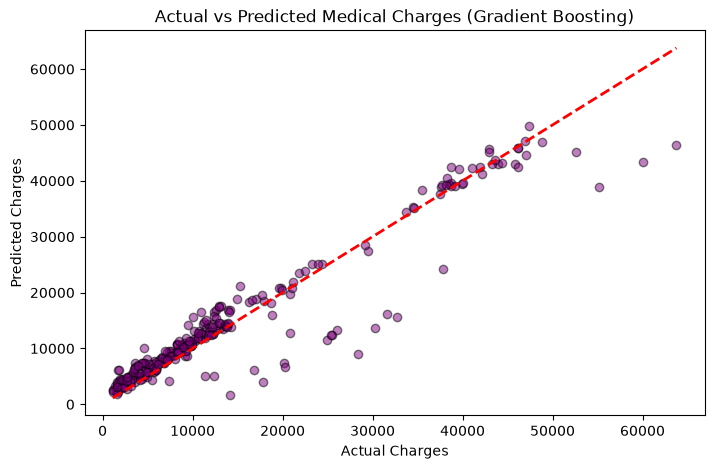

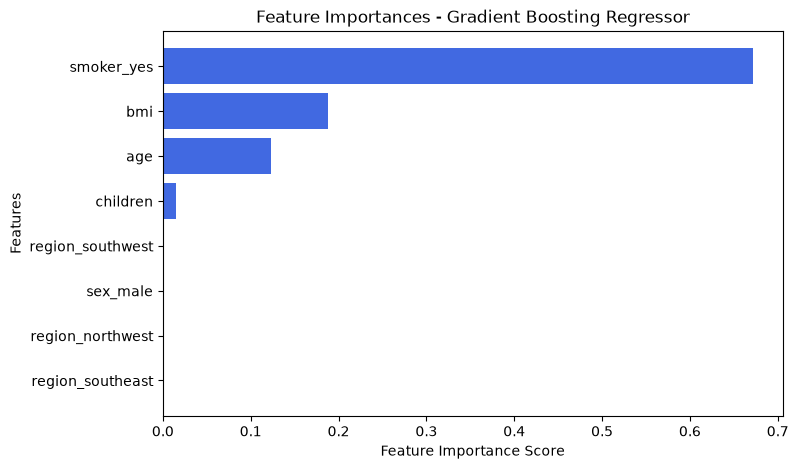

In [11]:
import matplotlib.pyplot as plt

# 1. Actual vs Predicted Plot for Gradient Boosting (Best Model)
plt.figure(figsize=(8, 5))
plt.scatter(y_test, gbr_test_pred, alpha=0.5, color='purple', edgecolor='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)
plt.title('Actual vs Predicted Medical Charges (Gradient Boosting)')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.show()

# 2. Feature Importance for Gradient Boosting
feature_importances = gbr.feature_importances_
features = X_train.columns

# Sort feature importances
sorted_idx = np.argsort(feature_importances)

plt.figure(figsize=(8, 5))
plt.barh(range(len(sorted_idx)), feature_importances[sorted_idx], align='center', color='royalblue')
plt.yticks(range(len(sorted_idx)), [features[i] for i in sorted_idx])
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title('Feature Importances - Gradient Boosting Regressor')
plt.show()

# (Model Training)

In [13]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Dataset (Assuming insurance.csv is in your directory)
df = pd.read_csv(r'C:\Users\WALEED TRADERS\Downloads\insurance.csv')

# Quick preprocessing (encoding categorical variables)
df = pd.get_dummies(df, drop_first=True)

X = df.drop('charges', axis=1)
y = df['charges']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Define Candidate Models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

trained_models = {}
performance_log = []

# 3. Train Models and Record Metrics
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    
    # Predictions
    y_pred = model.predict(X_test)
    
    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    performance_log.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    
    # Store trained model instance
    trained_models[name] = model
    
    # 4. Save trained model to disk
    filename = f"{name.lower().replace(' ', '_')}_model.pkl"
    joblib.dump(model, filename)
    print(f"Saved {filename} successfully!\n")

# Display final results table
results_df = pd.DataFrame(performance_log)
print("--- Model Training Summary ---")
print(results_df)

Training Linear Regression...
Saved linear_regression_model.pkl successfully!

Training Ridge Regression...
Saved ridge_regression_model.pkl successfully!

Training Random Forest...
Saved random_forest_model.pkl successfully!

Training Gradient Boosting...
Saved gradient_boosting_model.pkl successfully!

--- Model Training Summary ---
               Model          MAE         RMSE        R2
0  Linear Regression  4181.194474  5796.284659  0.783593
1   Ridge Regression  4193.585298  5800.434216  0.783283
2      Random Forest  2546.263793  4574.142511  0.865231
3  Gradient Boosting  2446.202802  4331.181281  0.879167


## Day 3 Model Comparison

--- Running 5-Fold Cross-Validation & Metric Evaluation ---

--- Final Model Comparison Summary ---
            Model  Mean CV R2  CV R2 Std  Mean CV RMSE    Test MAE   Test RMSE  Test R2
Linear Regression    0.738853   0.031060   6123.353823 4181.194474 5796.284659 0.783593
 Ridge Regression    0.738843   0.031040   6123.498935 4193.585298 5800.434216 0.783283
    Random Forest    0.829561   0.025240   4946.266590 2546.263793 4574.142511 0.865231
Gradient Boosting    0.849366   0.027944   4644.824070 2446.202802 4331.181281 0.879167


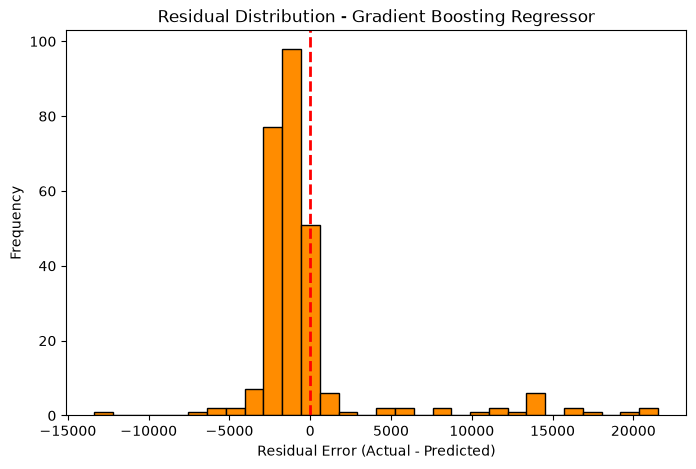

In [14]:
from sklearn.model_selection import cross_val_score, KFold

# Setup 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

comparison_results = []

print("--- Running 5-Fold Cross-Validation & Metric Evaluation ---")
for name, model in trained_models.items():
    # Cross-validation R2 scores
    cv_r2_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
    cv_rmse_scores = np.sqrt(-cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_mean_squared_error'))
    
    # Test predictions for final evaluation
    y_pred = model.predict(X_test)
    test_mae = mean_absolute_error(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    test_r2 = r2_score(y_test, y_pred)
    
    comparison_results.append({
        "Model": name,
        "Mean CV R2": cv_r2_scores.mean(),
        "CV R2 Std": cv_r2_scores.std(),
        "Mean CV RMSE": cv_rmse_scores.mean(),
        "Test MAE": test_mae,
        "Test RMSE": test_rmse,
        "Test R2": test_r2
    })

# Convert to DataFrame for clear comparison
comparison_df = pd.DataFrame(comparison_results)
print("\n--- Final Model Comparison Summary ---")
print(comparison_df.to_string(index=False))

# Plotting Residuals for the Best Model (Gradient Boosting)
residuals = y_test - trained_models['Gradient Boosting'].predict(X_test)

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, color='darkorange', edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)
plt.title('Residual Distribution - Gradient Boosting Regressor')
plt.xlabel('Residual Error (Actual - Predicted)')
plt.ylabel('Frequency')
plt.show()